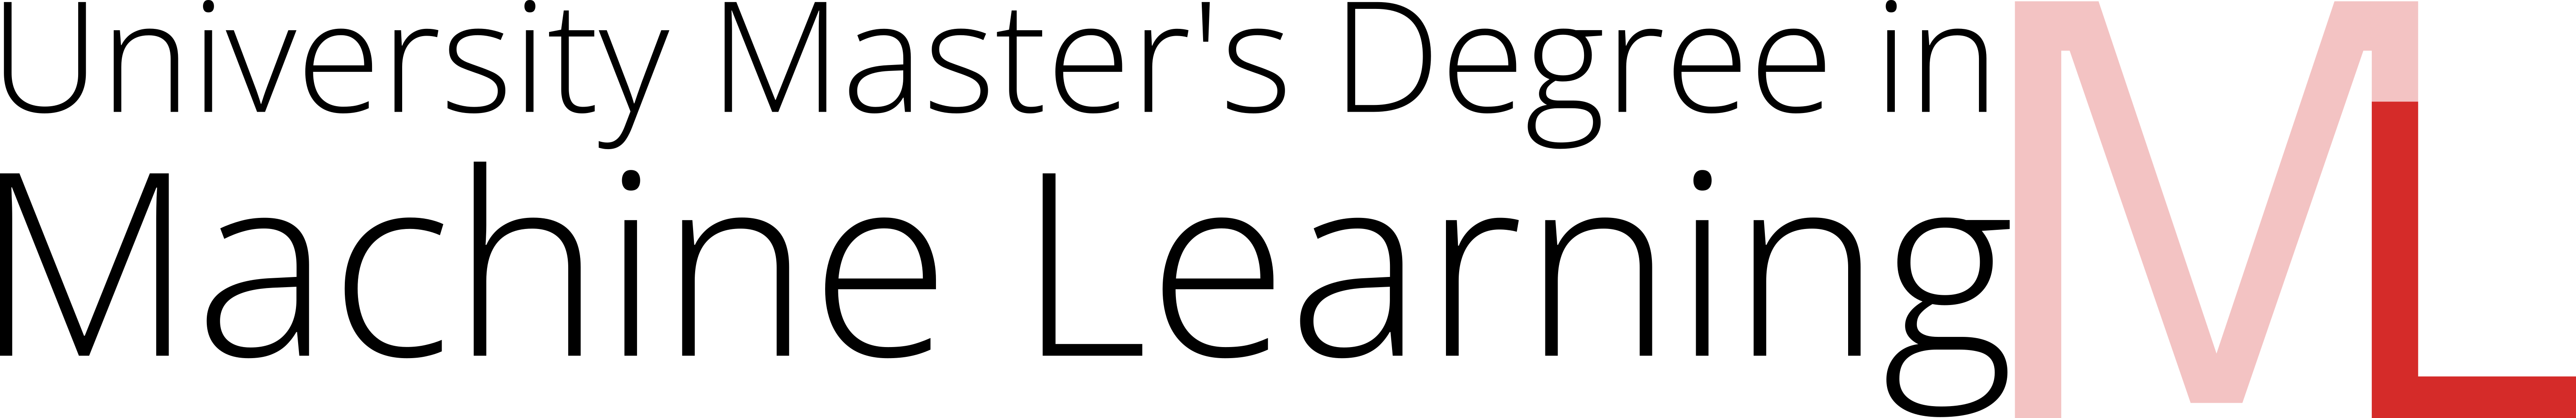

In this notebook we will work with **Datasets** and **Dataloaders** in PyTorch. Specifically, we will use a small dataset of dog and cat images, which we will load, process, and use to train an MLP in order to predict which animal appears in the image.

After having seen that an MLP can learn problems such as MNIST or Fashion-MNIST… **will it also be able to learn from more complex images?**


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from matplotlib import pyplot as plt
import os #for managing files, folders, etc.

In [2]:
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms

In [3]:
#If you are working on Colab, use this code to clone the dataset into your memory. Otherwise, download from MiAulario
#!git clone https://github.com/danielpaternain/cat_dog_small

Take a look at the dataset we will be working with. The dataset is organized into folders: at the first level, we have the **train** and **test** splits (we could also include a third **validation** folder here), and inside each of these, the images are further separated into subfolders by class. Later on, we will see that this distribution is quite standard, and PyTorch provides us with convenient functionality to load this type of dataset efficiently.


In the following code, we are going to use the functionalities of the **os** library to work with files and directories. A very useful function is **os.listdir**, which takes a path as a parameter and returns the list of files or folders contained in that path.


In [4]:
folder_class1 = os.listdir('cat_dog_small/train/cat')
len(folder_class1), folder_class1[0]

(500, 'cat.106.jpg')

In [5]:
folder_class2 = os.listdir('cat_dog_small/train/dog')
len(folder_class2), folder_class2[0]

(500, 'dog.10002.jpg')

As you can see, our dataset consists of **1000 training images**, with **500 from each class**. In addition, the size of each image is different.


In [6]:
im1 = plt.imread('cat_dog_small/train/cat/' + folder_class1[torch.randint(0, len(folder_class1), (1,))])
print(im1.shape)
im2 = plt.imread('cat_dog_small/train/cat/' + folder_class1[torch.randint(0, len(folder_class1), (1,))])
print(im2.shape)

(224, 300, 3)
(307, 410, 3)


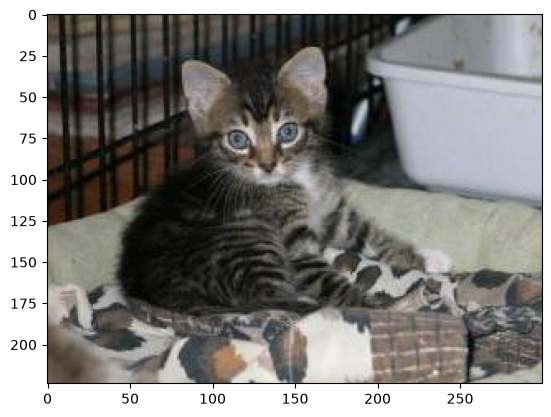

In [7]:
plt.imshow(im1)

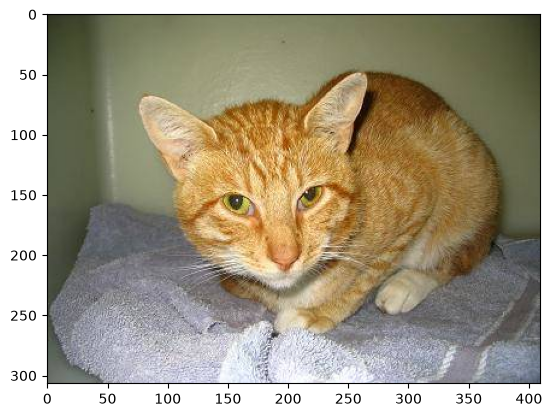

In [8]:
plt.imshow(im2)

To properly handle the image dataset, let’s start by defining our custom dataset **CatDogDS**, inheriting from PyTorch’s `Dataset` class. Instructions:

* ****init****: the constructor will receive the path to the training dataset `'cat_dog_small/train'`. Create a variable containing a list of all files corresponding to cats and another list for all files corresponding to dogs.
* ****len****: implement the functionality to return the length of the dataset.
* ****getitem****: based on the parameter `idx`, you should read an image and return its corresponding label. To set a criterion (you could choose another), assume that cats are class 0 and dogs are class 1. Since the dataset is ordered (the dataloader will shuffle it), the first indices (up to 499 in this specific case) correspond to cat samples and the following indices to dogs. Try to write the code as generally as possible.


In [9]:
class CatDogDS(Dataset):
    def __init__(self, path):
        self.path = path
        
        self.catFiles = os.listdir(os.path.join(path, 'cat'))
        self.dogFiles = os.listdir(os.path.join(path, 'dog'))

    def __len__(self):
        return len(self.catFiles) + len(self.dogFiles)

    def __getitem__(self, idx):
        if idx < len(self.catFiles):
            img_path = os.path.join(self.path, 'cat', self.catFiles[idx])
            return plt.imread(img_path), 0
        
        else:
            dog_idx = idx - len(self.catFiles)
            img_path = os.path.join(self.path, 'dog', self.dogFiles[dog_idx])
            return plt.imread(img_path), 1

Test your dataset here.

1


(<matplotlib.image.AxesImage at 0x7bcb201591d0>, None)

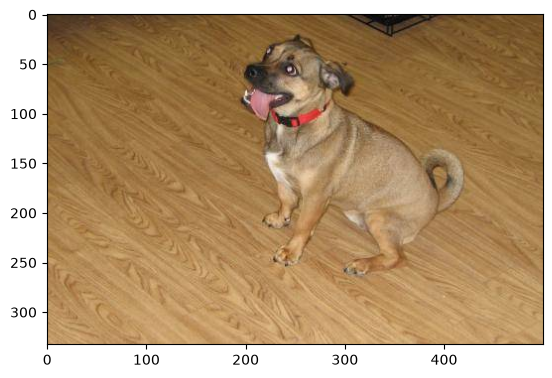

In [10]:
ds = CatDogDS('cat_dog_small/train')
sample = torch.randint(0, len(ds), (1,))
plt.imshow(ds[sample][0]), print(ds[sample][1])


As you can see, the images loaded in the dataset are the original ones, in RGB, and with varying dimensions. This is not entirely useful since our neural networks require a fixed input size. Moreover, the images in the dataset are in **matplotlib (numpy) format** and need to be converted to tensors. This is where transformations come into play.

Add the following code to the constructor of the Dataset (`dim` will be a new parameter of the constructor), and then in `__getitem__` apply `self.t(image)` before the return.


In [11]:
class CatDogDS(Dataset):
    def __init__(self, path, dim):
        self.path = path
      
        self.catFiles = os.listdir(os.path.join(path, 'cat'))
        self.dogFiles = os.listdir(os.path.join(path, 'dog'))

        self.t = transforms.Compose([transforms.ToTensor(),
                             transforms.Grayscale(),
                             transforms.Resize([dim, dim])])

    def __len__(self):
        return len(self.catFiles) + len(self.dogFiles)

    def __getitem__(self, idx):
        if idx < len(self.catFiles):
            img_path = os.path.join(self.path, 'cat', self.catFiles[idx])
            return self.t(plt.imread(img_path).copy()), 0
        
        else:
            dog_idx = idx - len(self.catFiles)
            img_path = os.path.join(self.path, 'dog', self.dogFiles[dog_idx])
            return self.t(plt.imread(img_path).copy()), 1

Test it. 

In [12]:
ds = CatDogDS('cat_dog_small/train', 64)
sample = torch.randint(0, len(ds), (1,))
print(ds[sample][0].shape)
print(ds[sample][1])

torch.Size([1, 64, 64])
1


Finally, add a last (custom) transformation to **vectorize the images**, since this is the only way to feed them into an MLP. Add the following to the list of transformations:


In [13]:
custom_tr = transforms.Lambda(lambda x: x.view(-1))

In [14]:
class CatDogDS(Dataset):
    def __init__(self, path, dim):
        self.path = path
        self.catFiles = os.listdir(os.path.join(path, 'cat'))
        self.dogFiles = os.listdir(os.path.join(path, 'dog'))

        self.t = transforms.Compose([
            transforms.ToTensor(),
            transforms.Grayscale(),
            transforms.Resize([dim, dim]),
            transforms.Lambda(lambda x: x.view(-1))  # Flatten (1, H, W) -> (H * W,)
        ])

    def __len__(self):
        return len(self.catFiles) + len(self.dogFiles)

    def __getitem__(self, idx):
        if idx < len(self.catFiles):
            img_path = os.path.join(self.path, 'cat', self.catFiles[idx])
            img = plt.imread(img_path)
            return self.t(img.copy()), 0
        else:
            dog_idx = idx - len(self.catFiles)
            img_path = os.path.join(self.path, 'dog', self.dogFiles[dog_idx])
            img = plt.imread(img_path)
            return self.t(img.copy()), 1

In [15]:
class CatDogDS(Dataset):
    def __init__(self, path, dim):
        self.path = path
      
        self.catFiles = os.listdir(os.path.join(path, 'cat'))
        self.dogFiles = os.listdir(os.path.join(path, 'dog'))

        self.t = transforms.Compose([transforms.ToTensor(),
                             transforms.Grayscale(),
                             transforms.Resize([dim, dim]),
                             transforms.Lambda(lambda x: x.view(-1))])

    def __len__(self):
        return len(self.catFiles) + len(self.dogFiles)

    def __getitem__(self, idx):
        if idx < len(self.catFiles):
            img_path = os.path.join(self.path, 'cat', self.catFiles[idx])
            return self.t(plt.imread(img_path).copy()), 0
        
        else:
            dog_idx = idx - len(self.catFiles)
            img_path = os.path.join(self.path, 'dog', self.dogFiles[dog_idx])
            return self.t(plt.imread(img_path).copy()), 1

In [16]:
ds = CatDogDS('cat_dog_small/train', 64)
sample = torch.randint(0, len(ds), (1,))
print(ds[sample][0].shape), print(ds[sample][1])

torch.Size([4096])
0


(None, None)

Now, split the generated dataset into two datasets, **ds_train** and **ds_val**, with an 80% / 20% distribution, respectively.


In [17]:
train_size = int(0.8 * len(ds))
val_size   = len(ds) - train_size
ds_train, ds_val = random_split(ds, [train_size, val_size])

In [18]:
print(len(ds_train)), print(len(ds_val))

800
200


(None, None)

Once the datasets are created, we can generate the **dataloaders**, which will be responsible for handling the batches. Check the size of the generated batches.


In [19]:
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True)
dl_val   = DataLoader(ds_val,   batch_size=32, shuffle=False)

In [20]:
size = 0
for batch_x, batch_y in dl_train:
  size += batch_x.shape[0]
  print(batch_x.shape), print(batch_y.shape)
print("Total size: ", size)

torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])
torch.Size([32, 4096])
torch.Size([32])


### Short Assignment

Create an MLP with one or more hidden layers. Implement the training loop that iterates over the batches and computes **error** and **accuracy** on both the training and validation sets.

Questions to analyze:

* What do you observe?
* Is your MLP able to learn from the training data?
* How many parameters are being trained?
* Is it able to generalize to unseen data?
* How does the image dimension affect performance?
* Would incorporating color provide any benefit?

**Maximum length:** 2 pages


In [21]:
class MLP(nn.Module):
    def __init__(self, input_size, neuron_list, num_classes=1):
        super(MLP, self).__init__()
        current_size = input_size
        hidden_layers = []
        for hidden_layer in neuron_list:
            hidden_layers.append(nn.Linear(current_size, hidden_layer))
            hidden_layers.append(nn.ReLU())
            current_size = hidden_layer
        hidden_layers.append(nn.Linear(current_size, num_classes))
        self.layers = nn.Sequential(*hidden_layers)

    def forward(self, x):
        return self.layers(x)


def compute_metrics(model, dataloader, criterion):
    """Computes average BCE loss and binary classification accuracy over a DataLoader."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            y_batch = y_batch.unsqueeze(1).float()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            running_loss += loss.item() * X_batch.size(0)

            # Binary classification prediction threshold at 0 logits
            preds = (logits > 0).float()
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc


def train_model(model, train_loader, val_loader, epochs=30, lr=1e-3):
    results = {
        'train loss': [],
        'val loss': [],
        'train acc': [],
        'val acc': []
    }
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            y_batch = y_batch.unsqueeze(1).float()
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

        # Evaluate epoch performance
        tr_loss, tr_acc = compute_metrics(model, train_loader, criterion)
        val_loss, val_acc = compute_metrics(model, val_loader, criterion)

        results['train loss'].append(tr_loss)
        results['val loss'].append(val_loss)
        results['train acc'].append(tr_acc)
        results['val acc'].append(val_acc)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | "
              f"Train Loss: {tr_loss:.4f} - Train Acc: {tr_acc*100:.1f}% | "
              f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.1f}%")

    return results

In [22]:
if __name__ == '__main__':
    DIM = 64
    INPUT_SIZE = DIM * DIM  # 64 x 64 = 4096

    full_ds = CatDogDS('cat_dog_small/train', dim=DIM)
    
    # 80/20 Train-Validation Split
    val_size = int(0.2 * len(full_ds))
    train_size = len(full_ds) - val_size
    ds_train, ds_val = random_split(full_ds, [train_size, val_size])

    dl_train = DataLoader(ds_train, batch_size=32, shuffle=True)
    dl_val = DataLoader(ds_val, batch_size=32, shuffle=False)

    model = MLP(input_size=INPUT_SIZE, neuron_list=[128, 64], num_classes=1)
    
    print(f"Total Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    history = train_model(model, dl_train, dl_val, epochs=30, lr=1e-3)

Total Parameters: 532,737
Epoch 01/30 | Train Loss: 0.7128 - Train Acc: 49.5% | Val Loss: 0.7058 - Val Acc: 52.0%
Epoch 02/30 | Train Loss: 0.6840 - Train Acc: 58.6% | Val Loss: 0.6877 - Val Acc: 51.5%
Epoch 03/30 | Train Loss: 0.6810 - Train Acc: 58.4% | Val Loss: 0.6847 - Val Acc: 55.5%
Epoch 04/30 | Train Loss: 0.6740 - Train Acc: 60.9% | Val Loss: 0.6820 - Val Acc: 54.0%
Epoch 05/30 | Train Loss: 0.6714 - Train Acc: 60.8% | Val Loss: 0.6816 - Val Acc: 58.0%
Epoch 06/30 | Train Loss: 0.6641 - Train Acc: 58.8% | Val Loss: 0.6752 - Val Acc: 57.5%
Epoch 07/30 | Train Loss: 0.6598 - Train Acc: 61.8% | Val Loss: 0.6733 - Val Acc: 64.0%
Epoch 08/30 | Train Loss: 0.6567 - Train Acc: 63.9% | Val Loss: 0.6714 - Val Acc: 64.5%
Epoch 09/30 | Train Loss: 0.6618 - Train Acc: 61.9% | Val Loss: 0.6785 - Val Acc: 61.5%
Epoch 10/30 | Train Loss: 0.6389 - Train Acc: 64.5% | Val Loss: 0.6689 - Val Acc: 56.0%
Epoch 11/30 | Train Loss: 0.6495 - Train Acc: 61.8% | Val Loss: 0.6852 - Val Acc: 54.5%
Epoch 

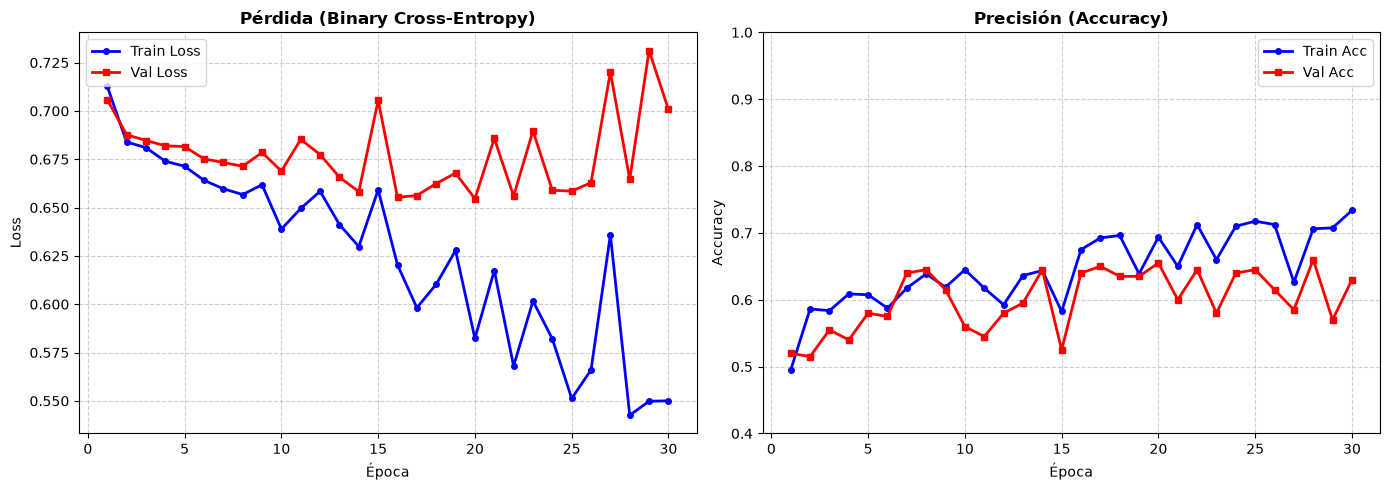

In [23]:
import matplotlib.pyplot as plt

def plot_history(history):
    epochs = range(1, len(history['train loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Gráfica 1: Pérdida (Loss) ---
    axes[0].plot(epochs, history['train loss'], 'b-o', label='Train Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs, history['val loss'], 'r-s', label='Val Loss', linewidth=2, markersize=4)
    axes[0].set_title('Pérdida (Binary Cross-Entropy)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # --- Gráfica 2: Precisión (Accuracy) ---
    axes[1].plot(epochs, history['train acc'], 'b-o', label='Train Acc', linewidth=2, markersize=4)
    axes[1].plot(epochs, history['val acc'], 'r-s', label='Val Acc', linewidth=2, markersize=4)
    axes[1].set_title('Precisión (Accuracy)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Accuracy')
    # Fijamos el eje Y para ver con claridad el rendimiento (0.4 a 1.0)
    axes[1].set_ylim(0.4, 1.0)
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

# Llamada a la función con los resultados de tu entrenamiento
plot_history(history)

=== Corriendo Experimentos de Dimensión ===
Entrenando Dimensión 32x32 | Params: 139,521...
Entrenando Dimensión 64x64 | Params: 532,737...
Entrenando Dimensión 128x128 | Params: 2,105,601...

=== Corriendo Experimentos de Color vs Grayscale ===
Entrenando Modo Grayscale | Params: 532,737...
Entrenando Modo RGB (Color) | Params: 1,581,313...


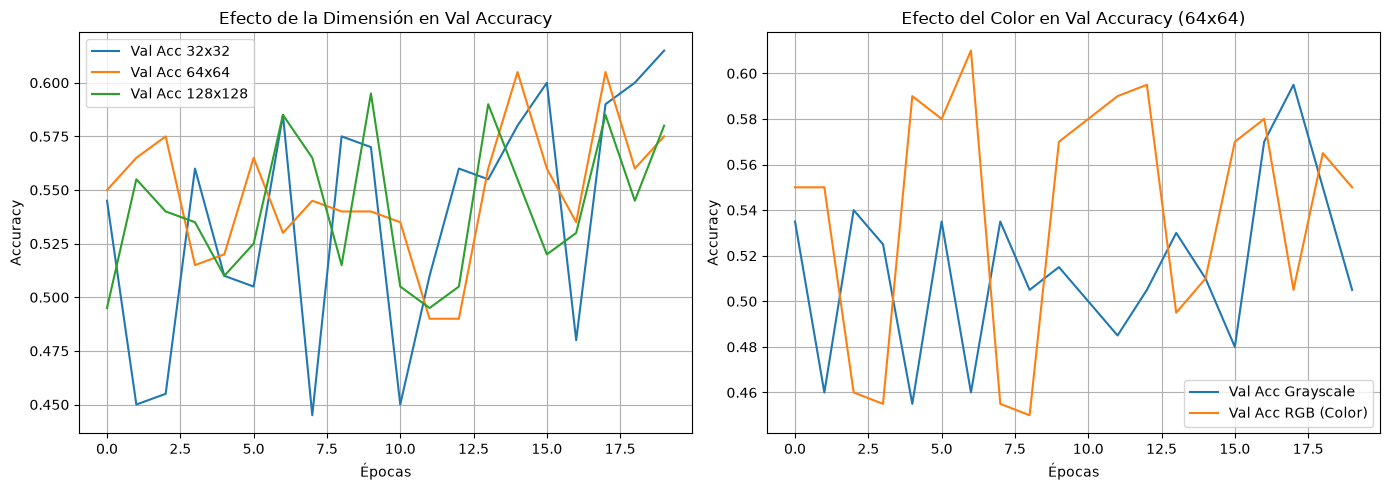

In [24]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

# Detectar GPU o CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# -------------------------------------------------------------
# 1. Dataset flexible (Soporta dimensión y color/grises)
# -------------------------------------------------------------
class CustomCatDogDS(Dataset):
    def __init__(self, path, dim=64, use_color=False):
        self.path = path
        self.cat_files = os.listdir(os.path.join(path, 'cat'))
        self.dog_files = os.listdir(os.path.join(path, 'dog'))
        self.use_color = use_color

        transform_list = [transforms.Resize([dim, dim], antialias=True)]
        
        if not use_color:
            transform_list.append(transforms.Grayscale(num_output_channels=1))
            
        transform_list.extend([
            transforms.ToTensor(),
            transforms.Lambda(lambda x: x.view(-1))  # Aplana a vector 1D
        ])

        self.t = transforms.Compose(transform_list)

    def __len__(self):
        return len(self.cat_files) + len(self.dog_files)

    def __getitem__(self, idx):
        if idx < len(self.cat_files):
            img_path = os.path.join(self.path, 'cat', self.cat_files[idx])
            label = 0
        else:
            dog_idx = idx - len(self.cat_files)
            img_path = os.path.join(self.path, 'dog', self.dog_files[dog_idx])
            label = 1

        img = Image.open(img_path).convert('RGB')
        return self.t(img), label


# -------------------------------------------------------------
# 2. Modelo MLP genérico
# -------------------------------------------------------------
class MLP(nn.Module):
    def __init__(self, input_size, hidden_list=[128, 64], num_classes=1):
        super(MLP, self).__init__()
        layers = []
        curr_size = input_size
        for h in hidden_list:
            layers.append(nn.Linear(curr_size, h))
            layers.append(nn.ReLU())
            curr_size = h
        layers.append(nn.Linear(curr_size, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# -------------------------------------------------------------
# 3. Bucle de Entrenamiento
# -------------------------------------------------------------
def train_experiment(model, train_loader, val_loader, epochs=20, lr=1e-3):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.unsqueeze(1).float().to(device)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

        # Evaluación
        model.eval()
        with torch.no_grad():
            # Metrics on Val
            val_loss, correct_val, total_val = 0.0, 0, 0
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.unsqueeze(1).float().to(device)
                logits = model(X_b)
                val_loss += criterion(logits, y_b).item() * X_b.size(0)
                preds = (logits > 0).float()
                correct_val += (preds == y_b).sum().item()
                total_val += y_b.size(0)

            # Metrics on Train
            train_loss, correct_tr, total_tr = 0.0, 0, 0
            for X_b, y_b in train_loader:
                X_b, y_b = X_b.to(device), y_b.unsqueeze(1).float().to(device)
                logits = model(X_b)
                train_loss += criterion(logits, y_b).item() * X_b.size(0)
                preds = (logits > 0).float()
                correct_tr += (preds == y_b).sum().item()
                total_tr += y_b.size(0)

        history['train_loss'].append(train_loss / total_tr)
        history['val_loss'].append(val_loss / total_val)
        history['train_acc'].append(correct_tr / total_tr)
        history['val_acc'].append(correct_val / total_val)

    return history


# -------------------------------------------------------------
# 4. Ejecución de los Experimentos
# -------------------------------------------------------------
if __name__ == '__main__':
    data_path = 'cat_dog_small/train'
    epochs = 20
    batch_size = 32

    # --- EXPERIMENTO 1: Efecto de la Dimensión (32x32, 64x64, 128x128) ---
    dims = [32, 64, 128]
    dim_results = {}

    print("=== Corriendo Experimentos de Dimensión ===")
    for d in dims:
        ds = CustomCatDogDS(data_path, dim=d, use_color=False)
        val_sz = int(0.2 * len(ds))
        train_ds, val_ds = random_split(ds, [len(ds) - val_sz, val_sz])
        
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        input_size = d * d  # 1 canal
        model = MLP(input_size=input_size, hidden_list=[128, 64]).to(device)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        
        print(f"Entrenando Dimensión {d}x{d} | Params: {params:,}...")
        dim_results[d] = train_experiment(model, train_loader, val_loader, epochs=epochs)

    # --- EXPERIMENTO 2: Efecto del Color (Grayscale vs RGB a 64x64) ---
    color_options = [False, True]
    color_results = {}

    print("\n=== Corriendo Experimentos de Color vs Grayscale ===")
    for use_color in color_options:
        mode_str = "RGB (Color)" if use_color else "Grayscale"
        ds = CustomCatDogDS(data_path, dim=64, use_color=use_color)
        val_sz = int(0.2 * len(ds))
        train_ds, val_ds = random_split(ds, [len(ds) - val_sz, val_sz])
        
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        input_size = (3 if use_color else 1) * 64 * 64
        model = MLP(input_size=input_size, hidden_list=[128, 64]).to(device)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad)

        print(f"Entrenando Modo {mode_str} | Params: {params:,}...")
        color_results[mode_str] = train_experiment(model, train_loader, val_loader, epochs=epochs)

    # -------------------------------------------------------------
    # 5. Generación de Gráficas Comparativas
    # -------------------------------------------------------------
    plt.figure(figsize=(14, 5))

    # Grafica Dimensión
    plt.subplot(1, 2, 1)
    for d, res in dim_results.items():
        plt.plot(res['val_acc'], label=f'Val Acc {d}x{d}')
    plt.title('Efecto de la Dimensión en Val Accuracy')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Grafica Color
    plt.subplot(1, 2, 2)
    for mode, res in color_results.items():
        plt.plot(res['val_acc'], label=f'Val Acc {mode}')
    plt.title('Efecto del Color en Val Accuracy (64x64)')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()